# Lesson 11 - All results, and five classes

Everything the project trained and found, in one notebook. **Nothing is trained here.** Every number and figure is
computed from the files the runs saved in `runs/` (`config.json`, `log.csv`, `eval/metrics.json`,
`eval/predictions.parquet`) and from `data/clips.parquet`, so the notebook runs in under a minute. The only
numbers typed in by hand are the dataset paper's (section 9.6).

The written version, with more detail, is `docs/experiment-log.md`. Lessons 03-10 explain how each experiment
works.

| Section | Question |
|---|---|
| 1. The data | how many clips and ships, and why the split is by ship |
| 2. The method | what the network hears and how it is trained |
| 3. All results at a glance | one table, and accuracy against the number of classes |
| 4. Twelve classes | the CNN against a simple baseline |
| 5. Ships, not ship types | why accuracy on new ships is low |
| 6. Reliability | trustworthy confidence, unknown ships, noise, another hydrophone, distance |
| 7. Distance and speed | how far away, how fast |
| 8. Nine classes | few-ship classes merged into "other" |
| 9. **Five classes** | the main result: fold 1, all 5 folds, and the dataset's own paper |
| 10. What it all means | |
| 11. Limitations and next steps | |
| 12. Reproduce | the commands behind every run |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import data as D
import metrics as M
from labels import load_config, load_groupings, load_groups
from paths import DATA_DIR, RUNS_DIR
from reliability import softmax

mel, table = D.open_features(DATA_DIR)      # mel.npy is only opened, not loaded; section 1 reads 5 clips of it

E2 = "class_f1_efficientnet_b0_vessel"      # the 12-class CNN; the other runs are named after it
E2_9, E2_5S, E2_5U = E2 + "_merged", E2 + "_shipsear5", E2 + "_uniqueship5"
E5, E7 = "class_f1_efficientnet_b0_leaky", E2 + "_hyd"
E3 = {g: E2 + f"_h{g}" for g in "ABC"}
FOLDS_5U = [E2_5U] + [f"class_f{k}_efficientnet_b0_vessel_uniqueship5" for k in range(2, 6)]

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e6e5e0", "axes.edgecolor": GREY, "axes.titlesize": 11, "font.size": 9.5})
NICE = {"passengership": "passenger ship", "pleasurecraft": "pleasure craft", "pilotvessel": "pilot vessel"}


def nice(c):
    return NICE.get(c, c)


def pct(x):
    return "–" if x is None or pd.isna(x) else f"{100 * x:.1f} %"


def pm(values, percent=True):
    """Mean ± standard deviation over folds (sample std, as everywhere in the experiment log)."""
    v = np.asarray(values, float)
    return f"{100 * v.mean():.1f} ± {100 * v.std(ddof=1):.1f} %" if percent else f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"


def config(run):
    return json.loads((RUNS_DIR / run / "config.json").read_text())


def log(run):
    return pd.read_csv(RUNS_DIR / run / "log.csv")


def metrics(run):
    return json.loads((RUNS_DIR / run / "eval" / "metrics.json").read_text())


def predictions(run):
    return pd.read_parquet(RUNS_DIR / run / "eval" / "predictions.parquet")


def baseline(run):
    """Class scores of a classical-baseline run (it writes its own metrics.json)."""
    c = json.loads((RUNS_DIR / run / "metrics.json").read_text())["class"]
    recall = [r for r in c["per_class_recall"].values() if r is not None]       # None: class not in the test set
    return {"classes": len(c["per_class_recall"]), "test clips": c["n_test"], "accuracy": c["accuracy"],
            "balanced accuracy": np.mean(recall), "macro-F1": c["macro_f1"]}


def test_probs(run):
    """Temperature-scaled probabilities and true classes of a class run's test clips (unknown-ship clips left out).
    Temperature scaling (section 6.1) changes how sure the model is, never which class it picks."""
    known, T = config(run)["known"], metrics(run)["calibration"]["temperature"]
    p = predictions(run)
    p = p[p.y_class >= 0].reset_index(drop=True)
    return softmax(p[[f"logit_{c}" for c in known]].to_numpy(), T), p.y_class.to_numpy(), p


def scores(run):
    """Every test score of a class run, computed from its saved predictions."""
    known, m, lg = config(run)["known"], metrics(run), log(run)
    prob, y, p = test_probs(run)
    pred, ranked = prob.argmax(1), np.argsort(-prob, 1)
    sure = np.argsort(-prob.max(1))                                   # most confident clips first
    ship = (p.label != "background").to_numpy()                       # per ship: average the clips of each ship
    per = pd.DataFrame(prob[ship]).assign(y=y[ship], mmsi=table.MMSI.to_numpy()[p.row.to_numpy()[ship]])
    per = per.groupby("mmsi")
    many = per.size()[per.size() >= 3].index                          # ships with at least 3 test clips
    by_dist = {k: v["accuracy"] for k, v in m["by_distance"].items()}
    return {"classes": len(known), "test clips": len(y), "accuracy": M.accuracy(y, pred),
            "balanced accuracy": np.nanmean(M.per_class_recall(y, pred, len(known))),
            "macro-F1": m["closed_set"]["macro_f1"],
            "top-2": np.mean((ranked[:, :2] == y[:, None]).any(1)), "top-3": np.mean((ranked[:, :3] == y[:, None]).any(1)),
            "most confident 20 %": M.accuracy(y[sure[:len(y) // 5]], pred[sure[:len(y) // 5]]),
            "most confident 10 %": M.accuracy(y[sure[:len(y) // 10]], pred[sure[:len(y) // 10]]),
            "per ship": M.accuracy(per.y.first().loc[many], per[list(range(len(known)))].mean().loc[many].to_numpy().argmax(1)),
            "ships (>= 3 clips)": len(many),
            "largest class": known[np.bincount(y).argmax()], "always the largest class": np.bincount(y).max() / len(y),
            "background share": np.mean(~ship), "random guess": 1 / len(known),
            "near": by_dist["near <700 m"], "mid": by_dist["mid 700-1400 m"], "far": by_dist["far >1400 m"],
            "ECE before": m["calibration"]["ece_before"], "ECE after": m["calibration"]["ece_after"],
            "T": m["calibration"]["temperature"],
            "recall": dict(zip(known, M.per_class_recall(y, pred, len(known)))),
            "epochs": len(lg), "best epoch": int(lg.epoch[lg.val_metric.idxmax()]),
            "minutes": lg.seconds.sum() / 60}


def confusion(runs):
    """Confusion counts of one run, or added up over several runs with the same classes (e.g. the 5 folds)."""
    runs = [runs] if isinstance(runs, str) else runs
    known, cm = config(runs[0])["known"], 0
    for run in runs:
        prob, y, _ = test_probs(run)
        cm = cm + M.confusion(y, prob.argmax(1), len(known))
    return cm, known


def plot_confusion(ax, cm, names, title):
    """Each row is one true class; each cell is the share of that class's clips given to the predicted class."""
    total = cm.sum(1, keepdims=True)
    share = np.divide(cm, total, out=np.full(cm.shape, np.nan), where=total > 0)
    ax.imshow(np.ma.masked_invalid(share), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), [nice(c) for c in names], rotation=45, ha="right")
    ax.set_yticks(range(len(names)), [nice(c) for c in names])
    for i in range(len(names)):
        for j in range(len(names)):
            if np.isfinite(share[i, j]):
                ax.text(j, i, f"{100 * share[i, j]:.0f}", ha="center", va="center", fontsize=8 if len(names) < 10 else 6.5,
                        color="white" if share[i, j] > 0.5 else "#0b0b0b")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title); ax.grid(False)


S = {run: scores(run) for run in [E2, E2_9, E2_5S, E5, E7, *E3.values(), *FOLDS_5U]}
print(f"loaded {len(S)} evaluated CNN runs")

loaded 13 evaluated CNN runs


## 1. The data

The UniqueShip 12-class / 5-hour subset: 5-second clips from two hydrophones of Ocean Networks Canada, each
labelled from the ships' AIS position reports. Every class has the same amount of audio (5 hours), but **not the same
number of different ships**. That turns out to matter more than anything else.

43,208 clips, 4,218 ships, 60 hours, 12 classes (11 ship types + background)


,clips,hours of audio,different ships
label,,,
background,"3,600",5.0,– (no ship)
pilot vessel,"3,601",5.0,2
dredger,"3,601",5.0,6
rescue,"3,600",5.0,23
passenger ship,"3,600",5.0,110
other,"3,601",5.0,169
sailing,"3,601",5.0,212
tanker,"3,601",5.0,233
fishing,"3,601",5.0,238


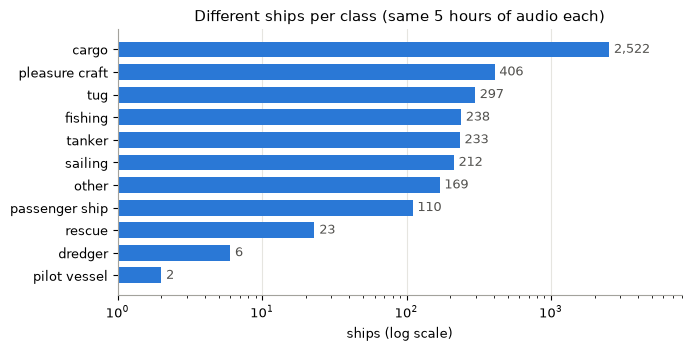

In [2]:
ship_clips = table[table.label != "background"]
per_class = pd.DataFrame({"clips": table.label.value_counts(), "hours of audio": table.label.value_counts() * 5 / 3600,
                          "different ships": ship_clips.groupby("label").MMSI.nunique()})
per_class = per_class.sort_values("different ships", na_position="first")
print(f"{len(table):,} clips, {ship_clips.MMSI.nunique():,} ships, {len(table) * 5 / 3600:.0f} hours, "
      f"{table.label.nunique()} classes (11 ship types + background)")
display(per_class.rename(index=nice).style.format({"clips": "{:,}", "hours of audio": "{:.1f}",
                                                   "different ships": "{:,.0f}"}, na_rep="– (no ship)"))

ships = per_class["different ships"].dropna()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([nice(c) for c in ships.index], ships, color=BLUE, height=0.7)
for i, n in enumerate(ships):
    ax.text(n * 1.08, i, f"{n:,.0f}", va="center", color=INK)
ax.set_xscale("log"); ax.set_xlim(1, 8000); ax.grid(axis="y", visible=False)
ax.set_title("Different ships per class (same 5 hours of audio each)"); ax.set_xlabel("ships (log scale)")
plt.tight_layout(); plt.show()

Pilot vessel has 2 ships in the whole dataset, dredger 6 and rescue 23; cargo has 2,522. A class heard from only
one or two ships can't be learned in general: the model can only learn *those* ships.

### What the network hears

Each clip becomes a log-mel spectrogram: 128 frequency bands (10 Hz at the bottom to 16 kHz at the top) by 501 time
steps of 10 ms. Below, one test clip of each class of the 5-class task (ships closer than 700 m). Ships show
as horizontal lines (engine and propeller tones) and broadband noise at low frequencies.

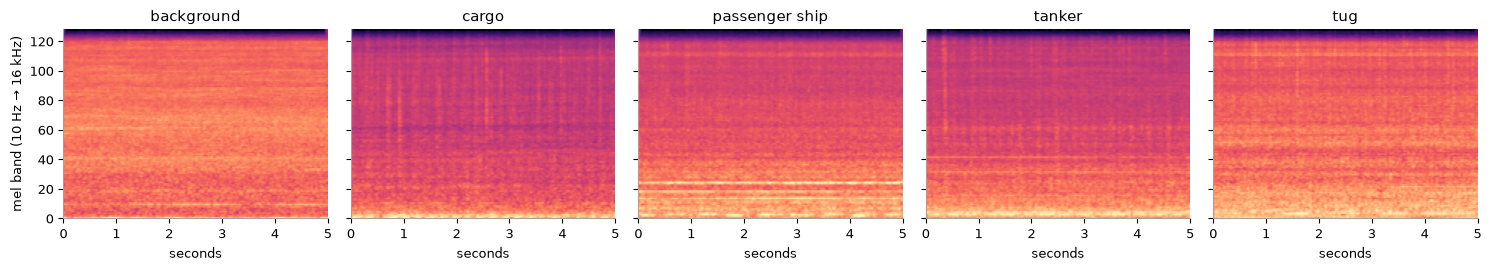

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 2.8), sharey=True)
test_f1, near = (table.split_f1 == "test").to_numpy(), (table.mean_distance < 700).to_numpy()
for ax, c in zip(axes, ["background", "cargo", "passengership", "tanker", "tug"]):
    i = np.flatnonzero(test_f1 & (table.label == c).to_numpy() & (near | (c == "background")))[0]
    ax.imshow(np.asarray(mel[i], np.float32), origin="lower", aspect="auto", cmap="magma", extent=[0, 5, 0, 128])
    ax.set_title(nice(c)); ax.set_xlabel("seconds"); ax.grid(False)
axes[0].set_ylabel("mel band (10 Hz → 16 kHz)")
plt.tight_layout(); plt.show()

### The fair split: no ship in two places

The dataset comes with 5 **vessel-disjoint** folds: every ship (MMSI) is in exactly one of train, validation and
test, so the test set measures recognition of ships the model has **never heard**. Background is split by recording
day. The check below confirms it for every fold, and shows what each fold's test set is made of.

In [4]:
folds = []
for k in range(1, 6):
    col = f"split_f{k}"
    test = table[table[col] == "test"]
    biggest_ship = test[test.label != "background"].MMSI.value_counts().iloc[0]
    share = test.label.value_counts(normalize=True)
    folds.append({"fold": k, "train clips": (table[col] == "train").sum(), "validation clips": (table[col] == "validation").sum(),
                  "test clips": len(test),
                  "ships in more than one split": int((ship_clips.groupby("MMSI")[col].nunique() > 1).sum()),
                  "largest class in test": f"{nice(share.index[0])} ({pct(share.iloc[0])})",
                  "largest single ship in test": f"{biggest_ship:,} clips ({pct(biggest_ship / len(test))})"})
folds = pd.DataFrame(folds).set_index("fold")
display(folds.style.format("{:,}", subset=["train clips", "validation clips", "test clips"]))

,train clips,validation clips,test clips,ships in more than one split,largest class in test,largest single ship in test
fold,,,,,,
1,"34,286","4,445","4,477",0,tanker (11.7 %),232 clips (5.2 %)
2,"31,913","5,636","5,659",0,pilot vessel (63.0 %),"3,565 clips (63.0 %)"
3,"35,948","3,624","3,636",0,rescue (13.4 %),232 clips (6.4 %)
4,"34,666","4,262","4,280",0,dredger (36.4 %),"1,560 clips (36.4 %)"
5,"36,019","3,584","3,605",0,sailing (12.7 %),72 clips (2.0 %)


No ship is in two splits of any fold. But the folds are not alike: fold 2's test set is 63 % **one** pilot vessel,
and fold 4's is 36 % one dredger. A score on such a test set is mostly a score on one ship (section 5).

## 2. The method

| | |
|---|---|
| Input | log-mel spectrogram of a 5-s clip, 128 bands × 501 frames, each band normalised with training-set statistics |
| Network | **EfficientNet-B0** pretrained on ImageNet (photos), adapted to 1 input channel, fine-tuned on ship sounds |
| Training | AdamW, learning rate 3e-4 (1 warm-up epoch, then cosine decay), weight decay 0.01, batch 32, dropout 0.3, SpecAugment (masks random frequency bands and time steps), each class weighted by 1 / its number of clips |
| Choosing the epoch | the epoch with the best **validation** macro-F1 is kept; training stops after 6 epochs without improvement (3 with `configs/fast.yaml`, at most 12 epochs) |
| Test set | opened once per final model, never used to choose settings |
| Calibration | temperature scaling, one number fitted on the validation set (section 6.1) |
| Hardware | laptop with an NVIDIA RTX 3050 (4 GB) and 16 GB RAM: 15-90 minutes per model |

The 9- and 5-class models use the **same network and settings**; only the labels change. The classical
baseline (E1) summarises each clip with simple statistics (per-band mean and standard deviation: 257 numbers; or
761 numbers with MFCCs and percentiles, "rich") and classifies them with gradient-boosted trees.

**Measures.** *Accuracy*: share of test clips classified correctly. *Balanced accuracy*: the mean of the per-class
recalls, so every class counts equally however many test clips it has. *Macro-F1*: the mean F1 score over the
classes, also counting every class equally. *Random guess*: 1 / number of classes.

## 3. All results at a glance

In [5]:
def cnn(run):
    return {k: S[run][k] for k in ("classes", "test clips", "accuracy", "balanced accuracy", "macro-F1")}


def over_folds(rows):
    return {"classes": rows[0]["classes"], "test clips": "5 folds",
            "accuracy": pm([r["accuracy"] for r in rows]), "balanced accuracy": pm([r["balanced accuracy"] for r in rows]),
            "macro-F1": pm([r["macro-F1"] for r in rows], percent=False)}


E1_folds = [baseline(f"baseline_f{k}") for k in range(1, 6)]
E1_9_folds = [baseline(f"baseline_merged_f{k}") for k in range(1, 6)]
glance = {
    "E1: classical baseline": baseline("baseline_f1"),
    "E1, 5 folds": over_folds(E1_folds),
    "E1 rich (761 numbers)": baseline("baseline_rich_f1"),
    "E2: CNN": cnn(E2),
    "E1-9: baseline, 9 classes": baseline("baseline_merged_f1"),
    "E1-9 rich": baseline("baseline_rich_merged_f1"),
    "E2-9: CNN, 9 classes": cnn(E2_9),
    "E2-5S: CNN, 5 size groups": cnn(E2_5S),
    "E2-5U: CNN, paper's 5 classes, fold 1": cnn(E2_5U),
    "E2-5U, 5 folds": over_folds([S[r] for r in FOLDS_5U]),
    "E5: leaky split (test ships heard in training)": cnn(E5),
    "E7: trained on one hydrophone, tested on the other": cnn(E7),
    **{f"E3 {g}: 3 classes held out as unknown": cnn(run) for g, run in E3.items()},
}
glance = pd.DataFrame.from_dict(glance, orient="index")
glance["test clips"] = [v if isinstance(v, str) else f"{v:,}" for v in glance["test clips"]]
for col in ("accuracy", "balanced accuracy"):
    glance[col] = [v if isinstance(v, str) else pct(v) for v in glance[col]]
glance["macro-F1"] = [v if isinstance(v, str) else f"{v:.3f}" for v in glance["macro-F1"]]
glance["random guess"] = [pct(1 / n) for n in glance.classes]
display(glance)

,classes,test clips,accuracy,balanced accuracy,macro-F1,random guess
E1: classical baseline,12,"4,477",31.8 %,29.3 %,0.277,8.3 %
"E1, 5 folds",12,5 folds,28.4 ± 9.1 %,32.3 ± 3.0 %,0.271 ± 0.067,8.3 %
E1 rich (761 numbers),12,"4,477",34.0 %,31.2 %,0.292,8.3 %
E2: CNN,12,"4,477",32.4 %,29.7 %,0.290,8.3 %
"E1-9: baseline, 9 classes",9,"4,477",34.6 %,36.9 %,0.349,11.1 %
E1-9 rich,9,"4,477",36.4 %,38.9 %,0.371,11.1 %
"E2-9: CNN, 9 classes",9,"4,477",36.7 %,39.7 %,0.370,11.1 %
"E2-5S: CNN, 5 size groups",5,"4,052",63.5 %,62.4 %,0.604,20.0 %
"E2-5U: CNN, paper's 5 classes, fold 1",5,"2,250",62.8 %,63.5 %,0.632,20.0 %
"E2-5U, 5 folds",5,5 folds,66.8 ± 4.4 %,65.5 ± 2.3 %,0.644 ± 0.020,20.0 %


Fold 1 unless a row says otherwise; E1 and E2 macro-F1 average 11 classes, because dredger has no test clips in
fold 1. E3 counts only the 9 known classes, and E7's smaller test set is 29 % background. **E5 is not a fair
number**: its test ships were also heard in training (section 5).

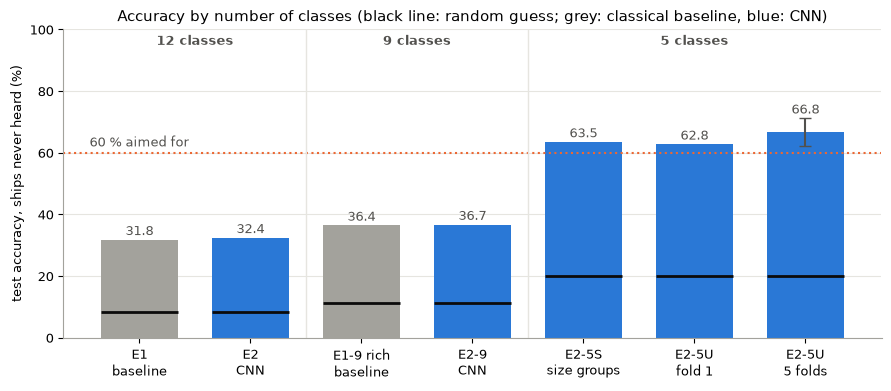

In [6]:
bars = [("E1\nbaseline", baseline("baseline_f1")["accuracy"], None, 12, GREY),
        ("E2\nCNN", S[E2]["accuracy"], None, 12, BLUE),
        ("E1-9 rich\nbaseline", baseline("baseline_rich_merged_f1")["accuracy"], None, 9, GREY),
        ("E2-9\nCNN", S[E2_9]["accuracy"], None, 9, BLUE),
        ("E2-5S\nsize groups", S[E2_5S]["accuracy"], None, 5, BLUE),
        ("E2-5U\nfold 1", S[E2_5U]["accuracy"], None, 5, BLUE),
        ("E2-5U\n5 folds", np.mean([S[r]["accuracy"] for r in FOLDS_5U]),
         np.std([S[r]["accuracy"] for r in FOLDS_5U], ddof=1), 5, BLUE)]
fig, ax = plt.subplots(figsize=(9, 4))
for i, (name, acc, sd, k, colour) in enumerate(bars):
    ax.bar(i, 100 * acc, width=0.7, color=colour, yerr=None if sd is None else 100 * sd, capsize=4, ecolor=INK)
    ax.text(i, 100 * acc + (100 * sd if sd else 0) + 1.5, f"{100 * acc:.1f}", ha="center", color=INK)
    ax.hlines(100 / k, i - 0.35, i + 0.35, color="#0b0b0b", lw=2)
ax.axhline(60, ls=":", color=ORANGE, lw=1.5)
ax.text(-0.45, 61, "60 % aimed for", color=INK, ha="left", va="bottom")
for x, label in ((0.5, "12 classes"), (2.5, "9 classes"), (5, "5 classes")):
    ax.text(x, 95, label, ha="center", color=INK, fontweight="bold")
for x in (1.5, 3.5):
    ax.axvline(x, color="#e6e5e0", lw=1)
ax.set_xticks(range(len(bars)), [b[0] for b in bars]); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_ylabel("test accuracy, ships never heard (%)")
ax.set_title("Accuracy by number of classes (black line: random guess; grey: classical baseline, blue: CNN)")
plt.tight_layout(); plt.show()

With 12 or 9 classes, the CNN and the simple baseline land at about the same accuracy, a little above a third.
With **5 broader classes** the same CNN passes the 60 % aimed for, on ships it has never heard.

## 4. Twelve classes: the CNN against the simple baseline

Recall per class (the share of each class's test clips classified correctly):

,ships in dataset,E1 baseline,E2 CNN,E5 leaky (heard ships)
background,–,0.76,0.62,0.87
cargo,"2,522",0.53,0.59,0.71
dredger,6,–,–,0.96
fishing,238,0.18,0.23,0.84
other,169,0.13,0.10,0.86
passenger ship,110,0.23,0.29,0.90
pilot vessel,2,0.00,0.00,1.00
pleasure craft,406,0.35,0.31,0.79
rescue,23,0.03,0.02,0.93
sailing,212,0.17,0.29,0.89


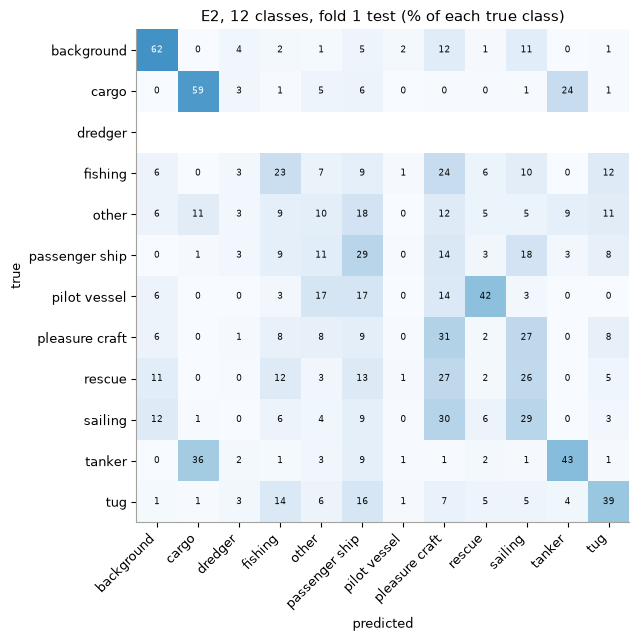

In [7]:
recall = pd.DataFrame({"E1 baseline": json.loads((RUNS_DIR / "baseline_f1" / "metrics.json").read_text())["class"]["per_class_recall"],
                       "E2 CNN": S[E2]["recall"], "E5 leaky (heard ships)": S[E5]["recall"]}).astype(float)
recall.insert(0, "ships in dataset", per_class["different ships"])
display(recall.rename(index=nice).style.format({"ships in dataset": "{:,.0f}"}, na_rep="–")
        .format(precision=2, na_rep="–", subset=["E1 baseline", "E2 CNN", "E5 leaky (heard ships)"]))

cm, known = confusion(E2)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
plot_confusion(ax, cm, known, "E2, 12 classes, fold 1 test (% of each true class)")
plt.tight_layout(); plt.show()

The CNN gains a few points on cargo, fishing, passenger ships and sailing, and loses a few on background and
tanker. The few-ship classes fail in both: pilot vessel (2 ships), rescue (23) and the mixed class "other". Dredger
has no test clips in fold 1 (empty row).

**What we tried to improve the 12-class CNN** (judged on validation only, the test set was not used):

In [8]:
tried = {}
for name, run in (("E2 (EfficientNet-B0)", E2), ("stronger regularisation", E2 + "_reg"),
                  ("MobileNetV3-Large", "class_f1_mobilenetv3_large_100_vessel")):
    lg = log(run)
    best = lg.val_metric.idxmax()
    tried[name] = {"best validation macro-F1": round(lg.val_metric[best], 3), "at epoch": int(lg.epoch[best]),
                   "epochs run": len(lg), "seconds per epoch": round(lg.seconds.mean()),
                   "clips per second": round(lg.clips_per_s.mean())}
display(pd.DataFrame.from_dict(tried, orient="index"))

,best validation macro-F1,at epoch,epochs run,seconds per epoch,clips per second
E2 (EfficientNet-B0),0.425,5,11,238,260
stronger regularisation,0.410,4,10,224,222
MobileNetV3-Large,0.381,7,10,145,401


Neither helped: stronger regularisation only slowed the memorising down, and MobileNetV3 trains about 1.5 times
faster but scores lower. Both architectures hit the same wall, which points to the data rather than the network.

## 5. Ships, not ship types

**The leaky split (E5)** has the same number of clips per split as E2, but shuffles clips without regard to which
ship they come from, so the test ships were also heard in training. Same network, same settings:

,E2: vessel-disjoint (fair),E5: leaky
test accuracy,32.4 %,85.8 %
test macro-F1,0.290,0.857
pilot vessel recall,0.0 %,100.0 %
rescue recall,1.7 %,93.2 %
ECE after temperature scaling,0.093,0.016


inflation from hearing the test ships before: 53.3 accuracy points


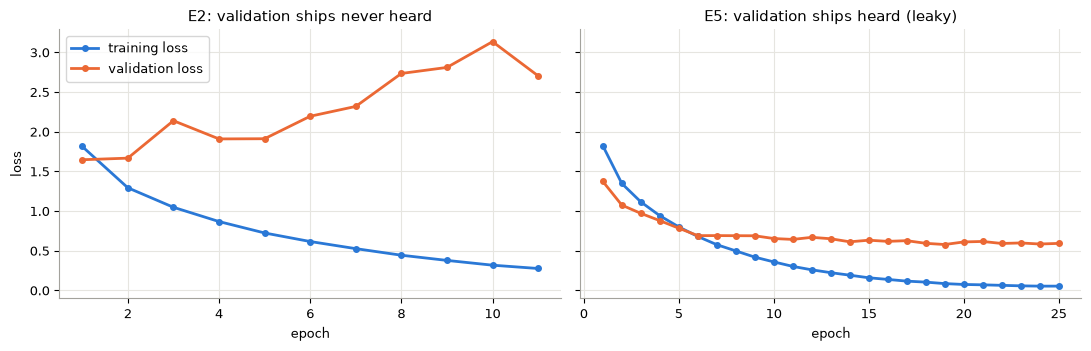

In [9]:
display(pd.DataFrame({
    "E2: vessel-disjoint (fair)": {"test accuracy": pct(S[E2]["accuracy"]), "test macro-F1": f"{S[E2]['macro-F1']:.3f}",
                                   "pilot vessel recall": pct(S[E2]["recall"]["pilotvessel"]),
                                   "rescue recall": pct(S[E2]["recall"]["rescue"]), "ECE after temperature scaling": f"{S[E2]['ECE after']:.3f}"},
    "E5: leaky": {"test accuracy": pct(S[E5]["accuracy"]), "test macro-F1": f"{S[E5]['macro-F1']:.3f}",
                  "pilot vessel recall": pct(S[E5]["recall"]["pilotvessel"]),
                  "rescue recall": pct(S[E5]["recall"]["rescue"]), "ECE after temperature scaling": f"{S[E5]['ECE after']:.3f}"}}))
print(f"inflation from hearing the test ships before: {100 * (S[E5]['accuracy'] - S[E2]['accuracy']):.1f} accuracy points")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, run, title in ((axes[0], E2, "E2: validation ships never heard"), (axes[1], E5, "E5: validation ships heard (leaky)")):
    lg = log(run)
    ax.plot(lg.epoch, lg.train_loss, color=BLUE, lw=2, marker="o", ms=4, label="training loss")
    ax.plot(lg.epoch, lg.val_loss, color=ORANGE, lw=2, marker="o", ms=4, label="validation loss")
    ax.set_title(title); ax.set_xlabel("epoch")
axes[0].set_ylabel("loss"); axes[0].legend()
plt.tight_layout(); plt.show()

**53 points of accuracy** come only from letting the model hear the test ships before. On the left, training loss
keeps falling while validation loss rises from epoch 2: the network gets better on the training ships and worse on
new ones. On the right, with the same ships on both sides, validation loss falls with training loss.

So the network tells **individual ships** apart very well (engine, propeller and hull give each ship its own
sound), but with few ships per class it doesn't learn what makes a *tanker* sound like a tanker in general. A
random split, as in some earlier work, would report 86 % for this model; the honest number for new ships is 32 %.

**Why the folds differ so much.** The classical baseline runs in minutes, so it was run on all 5 folds:

In [10]:
per_fold = folds[["test clips", "largest class in test", "largest single ship in test"]].copy()
per_fold["test clips"] = per_fold["test clips"].map("{:,}".format)
per_fold["E1, 12 classes"] = [pct(b["accuracy"]) for b in E1_folds]
per_fold["E1 rich"] = [pct(baseline(f"baseline_rich_f{k}")["accuracy"]) for k in range(1, 6)]
per_fold["E1-9, 9 classes"] = [pct(b["accuracy"]) for b in E1_9_folds]
display(per_fold)
print("E1, 12 classes:", pm([b["accuracy"] for b in E1_folds]), "   E1-9, 9 classes:", pm([b["accuracy"] for b in E1_9_folds]))

,test clips,largest class in test,largest single ship in test,"E1, 12 classes",E1 rich,"E1-9, 9 classes"
fold,,,,,,
1,"4,477",tanker (11.7 %),232 clips (5.2 %),31.8 %,34.0 %,34.6 %
2,"5,659",pilot vessel (63.0 %),"3,565 clips (63.0 %)",12.4 %,13.1 %,23.0 %
3,"3,636",rescue (13.4 %),232 clips (6.4 %),31.1 %,31.7 %,34.0 %
4,"4,280",dredger (36.4 %),"1,560 clips (36.4 %)",31.4 %,31.1 %,41.1 %
5,"3,605",sailing (12.7 %),72 clips (2.0 %),35.4 %,37.5 %,35.3 %


E1, 12 classes: 28.4 ± 9.1 %    E1-9, 9 classes: 33.6 ± 6.6 %


Fold 2 is the odd one out: 63 % of its test set is one pilot vessel, learned from 36 clips of the only other pilot
vessel. Merging the few-ship classes into "other" (section 8) lifts fold 2 and narrows the spread.

## 6. Reliability

### 6.1 Can we trust the confidence? Temperature scaling

A model is **calibrated** when, of the clips it labels with 70 % confidence, about 70 % are right. The *expected
calibration error* (ECE) measures the gap (0 = perfect). Temperature scaling divides the network's outputs by one
number T, fitted on the validation set; T > 1 means the raw model claims more certainty than it has.

,T,ECE before,ECE after
E2 (12 classes),2.18,0.330,0.093
E2-9 (9),2.55,0.374,0.107
E2-5S (5),1.50,0.110,0.031
"E2-5U (5), fold 1",2.25,0.184,0.026
E5 leaky,2.06,0.091,0.016
E7 other hydrophone,2.22,0.320,0.068
E3 A,1.60,0.227,0.084
E3 B,1.61,0.172,0.043
E3 C,1.82,0.276,0.115


MC dropout on E2 (20 passes): accuracy 32.5 %, ECE 0.325 (no better)


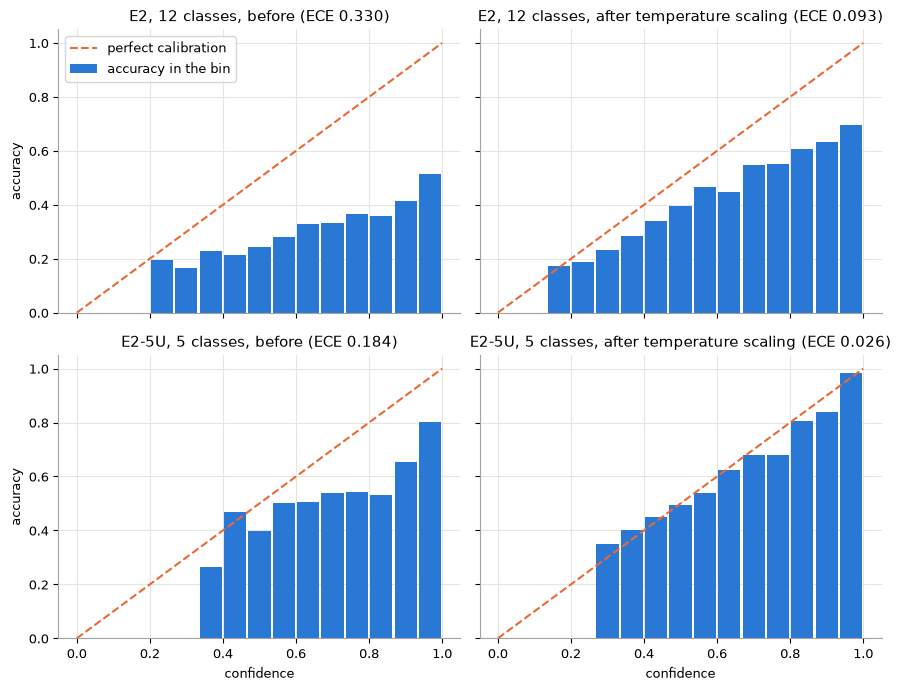

In [11]:
cal_runs = {"E2 (12 classes)": E2, "E2-9 (9)": E2_9, "E2-5S (5)": E2_5S, "E2-5U (5), fold 1": E2_5U,
            "E5 leaky": E5, "E7 other hydrophone": E7, **{f"E3 {g}": run for g, run in E3.items()}}
display(pd.DataFrame({name: {"T": round(S[run]["T"], 2), "ECE before": round(S[run]["ECE before"], 3),
                             "ECE after": round(S[run]["ECE after"], 3)} for name, run in cal_runs.items()}).T)
mc = metrics(E2)["mc_dropout"]
print(f"MC dropout on E2 ({mc['samples']} passes): accuracy {pct(mc['accuracy'])}, ECE {mc['ece']:.3f} (no better)")

n_bins = load_config()["ece_bins"]
centres = (np.arange(n_bins) + 0.5) / n_bins
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for row, (name, run) in zip(axes, (("E2, 12 classes", E2), ("E2-5U, 5 classes", E2_5U))):
    prob_T, y, p = test_probs(run)
    known = config(run)["known"]
    prob_1 = softmax(p[[f"logit_{c}" for c in known]].to_numpy())
    for ax, probs, when in ((row[0], prob_1, "before"), (row[1], prob_T, "after temperature scaling")):
        b = M.reliability_bins(probs, y, n_bins)
        ax.bar(centres, np.nan_to_num(b["acc"]), width=1 / n_bins - 0.006, color=BLUE, label="accuracy in the bin")
        ax.plot([0, 1], [0, 1], ls="--", color=ORANGE, lw=1.5, label="perfect calibration")
        ax.set_title(f"{name}, {when} (ECE {M.ece(probs, y, n_bins):.3f})")
    row[0].set_ylabel("accuracy")
axes[1, 0].set_xlabel("confidence"); axes[1, 1].set_xlabel("confidence"); axes[0, 0].legend(loc="upper left")
plt.tight_layout(); plt.show()

Before scaling, the bars sit below the diagonal: the model is overconfident. After scaling they follow it, for 12
classes and even more closely for 5. Monte Carlo dropout did not help, so temperature scaling is the method that
works here.

### 6.2 Answering only when confident

Confidence carries information: the more confident the model is, the more often it is right. A system that answers
only for its most confident clips, and says "not sure" otherwise, is right more often but answers fewer clips.

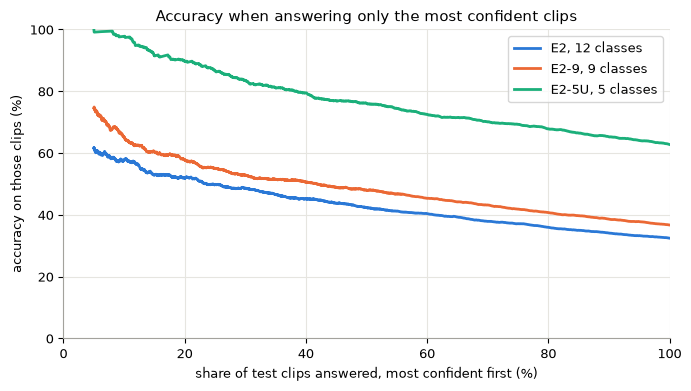

,E2,E2-9,E2-5S,"E2-5U, fold 1"
every clip,32.4 %,36.7 %,63.5 %,62.8 %
true class in the top 2,53.9 %,57.2 %,86.9 %,89.2 %
true class in the top 3,66.4 %,70.5 %,95.9 %,95.5 %
most confident 20 %,51.8 %,57.8 %,91.2 %,89.8 %
most confident 10 %,57.7 %,65.1 %,96.5 %,97.8 %


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
for (name, run), colour in zip((("E2, 12 classes", E2), ("E2-9, 9 classes", E2_9), ("E2-5U, 5 classes", E2_5U)),
                               (BLUE, ORANGE, AQUA)):
    prob, y, _ = test_probs(run)
    correct = (prob.argmax(1) == y)[np.argsort(-prob.max(1))]
    n = np.arange(1, len(y) + 1)
    start = len(y) // 20
    ax.plot(100 * n[start:] / len(y), 100 * np.cumsum(correct)[start:] / n[start:], color=colour, lw=2, label=name)
ax.set_xlabel("share of test clips answered, most confident first (%)"); ax.set_ylabel("accuracy on those clips (%)")
ax.set_ylim(0, 100); ax.set_xlim(0, 100); ax.legend(); ax.set_title("Accuracy when answering only the most confident clips")
plt.tight_layout(); plt.show()

display(pd.DataFrame({name: {"every clip": pct(S[run]["accuracy"]), "true class in the top 2": pct(S[run]["top-2"]),
                             "true class in the top 3": pct(S[run]["top-3"]),
                             "most confident 20 %": pct(S[run]["most confident 20 %"]),
                             "most confident 10 %": pct(S[run]["most confident 10 %"])}
                      for name, run in (("E2", E2), ("E2-9", E2_9), ("E2-5S", E2_5S), ("E2-5U, fold 1", E2_5U))}))

Each of these numbers must be reported with its definition; none of them is "the accuracy".

### 6.3 Combining the clips of one ship

A passing ship gives several 5-s clips. Averaging the (temperature-scaled) probabilities over all test clips of the
same ship and deciding once per ship, for ships with at least 3 test clips (background left out):

In [13]:
display(pd.DataFrame({name: {"per clip (every clip)": pct(S[run]["accuracy"]), "per ship, clips averaged": pct(S[run]["per ship"]),
                             "ships": S[run]["ships (>= 3 clips)"]}
                      for name, run in (("E2", E2), ("E2-9", E2_9), ("E2-5S", E2_5S), ("E2-5U, fold 1", E2_5U))}))

,E2,E2-9,E2-5S,"E2-5U, fold 1"
per clip (every clip),32.4 %,36.7 %,63.5 %,62.8 %
"per ship, clips averaged",40.1 %,41.9 %,70.1 %,77.9 %
ships,217,217,197,86


Deciding per ship adds 5-15 points, as in real use, where a ship is heard for minutes rather than 5 seconds.

### 6.4 Unknown ship types are not detected (E3)

Each E3 model is trained without 3 classes, whose test clips it should flag as "unknown". AUROC measures how well a
score separates unknown from known clips: 0.5 is a coin toss, 1.0 perfect.

In [14]:
names = {"msp": "max softmax probability", "energy": "energy", "mc_entropy": "MC dropout entropy",
         "mc_mi": "MC dropout mutual information"}
held = {g: ", ".join(nice(c) for c in members) for g, members in load_groups().items()}
auroc = pd.DataFrame({f"{g} ({held[g]})": {names[s]: metrics(run)["open_set"][s]["auroc"] for s in names}
                      for g, run in E3.items()})
auroc["mean"] = auroc.mean(axis=1)
display(auroc.round(2))

,"A (fishing, sailing, tanker)","B (cargo, pleasure craft, rescue)","C (tug, passenger ship, other)",mean
max softmax probability,0.50,0.58,0.51,0.53
energy,0.52,0.58,0.57,0.56
MC dropout entropy,0.51,0.59,0.51,0.53
MC dropout mutual information,0.48,0.47,0.56,0.50


Every score is close to 0.5: the model is as confident on ship types it has never heard as on known ones. This fits
section 5: if it can't capture what a known class sounds like in general, it can't notice a sound that fits no
known class either.

### 6.5 Noise makes the model worse and *more* sure of itself (E8)

White noise mixed into 1,000 test clips at falling signal-to-noise ratios (0 dB: noise as loud as the recording):

,accuracy,clips flagged unknown,clips
clean,34.6 %,5.4 %,1000
20.0 dB,22.5 %,3.5 %,1000
10.0 dB,15.8 %,2.9 %,1000
0.0 dB,13.0 %,0.8 %,1000


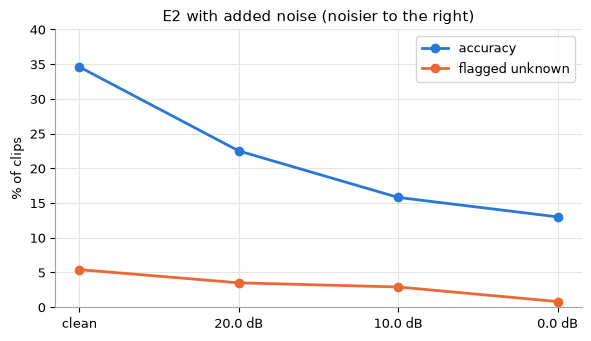

In [15]:
noise = pd.DataFrame(metrics(E2)["noise"]).T.astype({"n": int})
display(noise.assign(accuracy=noise.accuracy.map(pct), flagged_unknown=noise.flagged_unknown.map(pct))
        .rename(columns={"flagged_unknown": "clips flagged unknown", "n": "clips"}))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(noise.index, 100 * noise.accuracy.astype(float), color=BLUE, lw=2, marker="o", label="accuracy")
ax.plot(noise.index, 100 * noise.flagged_unknown.astype(float), color=ORANGE, lw=2, marker="o", label="flagged unknown")
ax.set_ylabel("% of clips"); ax.set_ylim(0, 40); ax.legend(); ax.set_title("E2 with added noise (noisier to the right)")
plt.tight_layout(); plt.show()

A reliable model would say "not sure" more often as the sound gets noisier. Ours does the opposite.

### 6.6 Another hydrophone costs about 7 points (E7)

E7 is trained on hydrophone 2523 only and tested on hydrophone 2556 (plus background). E2 is scored on exactly the
same test clips (E2 heard both hydrophones in training):

In [16]:
def on_2556(run):
    _, y, p = test_probs(run)
    hyd = table.hydrophone.fillna("").to_numpy()[p.row.to_numpy()]
    bg = (p.label == "background").to_numpy()
    right = (p.pred_class == p.label).to_numpy()
    every, ships_only = (hyd == D.HYDROPHONE_TEST) | bg, (hyd == D.HYDROPHONE_TEST) & ~bg
    return {"all clips": pct(right[every].mean()), "ship clips only": pct(right[ships_only].mean()),
            "clips (ship clips)": f"{every.sum():,} ({ships_only.sum():,})"}


display(pd.DataFrame({"E2, trained on both hydrophones": on_2556(E2), "E7, trained on hydrophone 2523 only": on_2556(E7)}).T)

,all clips,ship clips only,clips (ship clips)
"E2, trained on both hydrophones",41.1 %,32.6 %,"1,267 (905)"
"E7, trained on hydrophone 2523 only",40.2 %,25.9 %,"1,267 (905)"


On ship clips, changing the hydrophone costs about 7 points (part of it because E7 trains on fewer clips). The model
partly learns the microphone or the place, not only the ships.

### 6.7 Recognition gets worse with distance

,< 700 m,"700-1,400 m","> 1,400 m"
"E2, 12 classes",43.4 %,32.6 %,21.7 %
"E2-9, 9 classes",48.1 %,34.7 %,25.5 %
"E2-5S, 5 groups",70.3 %,67.8 %,53.3 %
"E2-5U, 5 classes",64.4 %,59.9 %,50.3 %
"E5, leaky",81.4 %,88.6 %,85.0 %


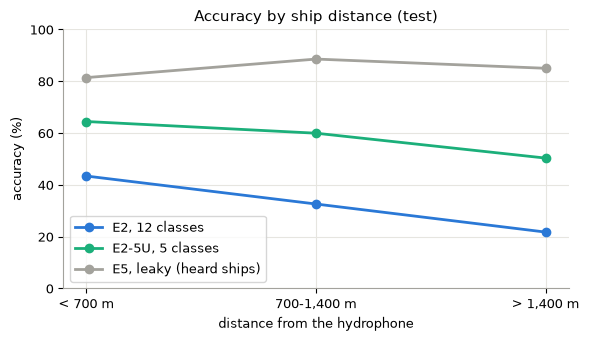

In [17]:
dist_runs = {"E2, 12 classes": E2, "E2-9, 9 classes": E2_9, "E2-5S, 5 groups": E2_5S, "E2-5U, 5 classes": E2_5U,
             "E5, leaky": E5}
display(pd.DataFrame({name: {"< 700 m": pct(S[run]["near"]), "700-1,400 m": pct(S[run]["mid"]),
                             "> 1,400 m": pct(S[run]["far"])} for name, run in dist_runs.items()}).T)
fig, ax = plt.subplots(figsize=(6, 3.5))
for (name, run), colour in zip((("E2, 12 classes", E2), ("E2-5U, 5 classes", E2_5U), ("E5, leaky (heard ships)", E5)),
                               (BLUE, AQUA, GREY)):
    ax.plot(["< 700 m", "700-1,400 m", "> 1,400 m"], [100 * S[run][k] for k in ("near", "mid", "far")],
            color=colour, lw=2, marker="o", label=name)
ax.set_ylim(0, 100); ax.set_ylabel("accuracy (%)"); ax.set_xlabel("distance from the hydrophone"); ax.legend()
ax.set_title("Accuracy by ship distance (test)")
plt.tight_layout(); plt.show()

For new ships, accuracy falls with distance as the ship's sound fades into the background noise. A ship heard
before (E5) is recognised even from far away.

## 7. Distance and speed

Mean error on ship clips of fold 1's test set, and distance also scored as classes of 250 m (0-2 km):

In [18]:
b1, b_rich = (json.loads((RUNS_DIR / r / "metrics.json").read_text()) for r in ("baseline_f1", "baseline_rich_f1"))
e9 = predictions("distance_f1_efficientnet_b0_vessel")
true_m = table.mean_distance.to_numpy(float)[e9.row.to_numpy()]
ok = np.isfinite(true_m) & (e9.label != "background").to_numpy()
e9_bins = M.distance_bin_report(true_m[ok], e9.pred_distance_m.to_numpy()[ok])


def regression_row(dist_mae, speed_mae, bins):
    return {"distance error (m)": round(dist_mae), "speed error (knots)": round(speed_mae, 2),
            "right 250 m bin": pct(bins["bin_accuracy"]), "right bin or the next": pct(bins["within_one_bin"]),
            "near (< 700 m) / far, balanced": pct(bins["near_far_balanced_accuracy"])}


display(pd.DataFrame({
    "always guess the median": regression_row(b1["distance"]["baseline_mae"], b1["speed"]["baseline_mae"], b1["distance"]["baseline_bins"]),
    "E1 baseline": regression_row(b1["distance"]["mae"], b1["speed"]["mae"], b1["distance"]),
    "E1 rich": regression_row(b_rich["distance"]["mae"], b_rich["speed"]["mae"], b_rich["distance"]),
    "E9 / E10 CNN": regression_row(metrics("distance_f1_efficientnet_b0_vessel")["regression"]["distance"]["mae"],
                                   metrics("speed_f1_efficientnet_b0_vessel")["regression"]["speed"]["mae"], e9_bins)}).T)

,distance error (m),speed error (knots),right 250 m bin,right bin or the next,"near (< 700 m) / far, balanced"
always guess the median,403,3.64,19.2 %,54.1 %,50.0 %
E1 baseline,274,2.96,28.2 %,71.4 %,72.3 %
E1 rich,270,2.94,29.7 %,72.7 %,73.1 %
E9 / E10 CNN,275,2.94,29.8 %,72.7 %,75.6 %


Both methods beat guessing the median, and the CNN is no better than the classical baseline, except slightly at
telling near from far.

## 8. Nine classes: few-ship classes merged into "other"

Pilot vessel (2 ships), dredger (6) and rescue (23) can't be learned from so few ships, so E2-9 trains and scores
them as "other" (`--merge-into-other pilotvessel dredger rescue`). Before training, the 12-class model's predictions
gave an **estimate**: add up the probabilities of the classes that are merged, and pick the largest.

In [19]:
def estimate(groups):
    """Accuracy of the 12-class model E2 asked a grouped question: the probabilities of each group's classes are
    added up, and clips of classes in no group are left out."""
    prob, y, p = test_probs(E2)
    known = config(E2)["known"]
    grouped = np.stack([prob[:, [known.index(c) for c in members]].sum(1) for members in groups.values()], 1)
    target = p.label.map({c: i for i, members in enumerate(groups.values()) for c in members})
    keep = target.notna().to_numpy()
    return M.accuracy(target[keep].astype(int), grouped[keep].argmax(1))


nine = {**{c: [c] for c in config(E2)["known"] if c not in ("pilotvessel", "dredger", "rescue", "other")},
        "other": ["other", "pilotvessel", "dredger", "rescue"]}


def compare(runs, estimates=None):
    rows = {}
    for name, run in runs.items():
        s = S[run]
        rows[name] = {"test clips": f"{s['test clips']:,}", "accuracy, every clip": pct(s["accuracy"]),
                      "balanced accuracy": pct(s["balanced accuracy"]), "macro-F1": f"{s['macro-F1']:.3f}",
                      "estimate before training (from E2)": pct(estimates.get(name)) if estimates else "–",
                      "always answering the largest class": f"{pct(s['always the largest class'])} ({nice(s['largest class'])})",
                      "random guess": pct(s["random guess"]),
                      "ships < 700 m / 700-1,400 m / > 1,400 m": " / ".join(f"{100 * s[k]:.0f}" for k in ("near", "mid", "far")) + " %",
                      "true class among the 2 most likely": pct(s["top-2"]),
                      "most confident 20 % / 10 % of clips": f"{100 * s['most confident 20 %']:.1f} / {100 * s['most confident 10 %']:.1f} %",
                      "per ship, clips averaged": f"{pct(s['per ship'])} ({s['ships (>= 3 clips)']} ships)",
                      "ECE before → after temperature scaling": f"{s['ECE before']:.3f} → {s['ECE after']:.3f} (T = {s['T']:.2f})",
                      "training": f"{s['epochs']} epochs (best {s['best epoch']}), {s['minutes']:.0f} min"}
    return pd.DataFrame(rows)


display(compare({"E2 (12 classes)": E2, "E2-9 (9 classes)": E2_9}, {"E2-9 (9 classes)": estimate(nine)}))
display(pd.DataFrame({"E2-9 recall": S[E2_9]["recall"]}).rename(index=nice).T.round(2))
print("classical baseline, 9 classes, 5 folds:", pm([b["accuracy"] for b in E1_9_folds]),
      "  macro-F1", pm([b["macro-F1"] for b in E1_9_folds], percent=False))
print(f"fold 1: E1-9 {pct(baseline('baseline_merged_f1')['accuracy'])}, E1-9 rich {pct(baseline('baseline_rich_merged_f1')['accuracy'])} "
      f"(macro-F1 {baseline('baseline_rich_merged_f1')['macro-F1']:.3f}), E2-9 CNN {pct(S[E2_9]['accuracy'])} (macro-F1 {S[E2_9]['macro-F1']:.3f})")

,E2 (12 classes),E2-9 (9 classes)
test clips,"4,477","4,477"
"accuracy, every clip",32.4 %,36.7 %
balanced accuracy,29.7 %,39.7 %
macro-F1,0.290,0.370
estimate before training (from E2),–,34.2 %
always answering the largest class,11.7 % (tanker),19.5 % (other)
random guess,8.3 %,11.1 %
"ships < 700 m / 700-1,400 m / > 1,400 m",43 / 33 / 22 %,48 / 35 / 25 %
true class among the 2 most likely,53.9 %,57.2 %
most confident 20 % / 10 % of clips,51.8 / 57.7 %,57.8 / 65.1 %


,background,cargo,fishing,other,passenger ship,pleasure craft,sailing,tanker,tug
E2-9 recall,0.76,0.59,0.28,0.11,0.24,0.29,0.28,0.56,0.46


classical baseline, 9 classes, 5 folds: 33.6 ± 6.6 %   macro-F1 0.333 ± 0.050
fold 1: E1-9 34.6 %, E1-9 rich 36.4 % (macro-F1 0.371), E2-9 CNN 36.7 % (macro-F1 0.370)


Merging helps a little (32 → 37 %), but the enlarged "other" class is now the largest and the hardest: it mixes many
kinds of ships, so it has no common sound to learn. With the rich features, gradient-boosted trees on hand-made
statistics are **as good as the CNN** on 9 classes: on ships it has never heard, the CNN brings no advantage here.

## 9. Five classes

Fewer, broader classes remove the hardest choices, and each class then contains more different ships. Two 5-class
models were trained, with the **same network and settings** as E2-9 (`configs/fast.yaml`); only the labels differ.

### 9.1 Two ways to choose 5 classes

- **E2-5S, size groups as in the ShipsEar dataset** (Santos-Domínguez et al., 2016): working and fishing vessels,
  small craft, passenger ships, large ships, no ship. "Other" is left out: it mixes many kinds of ships, so it fits
  no size group.
- **E2-5U, the 5 classes of the dataset's own paper** (UniqueShip, OCEANS 2026): background, cargo, passenger ship,
  tanker, tug. The other 7 classes are left out. It is the task the paper reports, so the two can be compared
  (section 9.6).

Both groupings are written in `configs/groups.yaml`:

In [20]:
groupings = load_groupings()
for name, title in (("shipsear5", "E2-5S: ShipsEar size groups"), ("uniqueship5", "E2-5U: the paper's 5 classes")):
    groups = groupings[name]
    rows = {}
    for g, members in groups.items():
        clips = table[table.label.isin(members)]
        rows[nice(g)] = {"classes": ", ".join(nice(c) for c in members), "clips": f"{len(clips):,}",
                         "different ships": "–" if g == "background" else f"{clips.MMSI.nunique():,}"}
    left_out = sorted(set(table.label.unique()) - {c for m in groups.values() for c in m})
    print(f"{title}   (left out: {', '.join(nice(c) for c in left_out) or 'nothing'})")
    display(pd.DataFrame(rows).T)

E2-5S: ShipsEar size groups   (left out: other)


,classes,clips,different ships
working,"fishing, tug, dredger","10,803",541
small,"pleasure craft, sailing, pilot vessel, rescue","14,402",643
passenger,passenger ship,"3,600",110
large,"cargo, tanker","7,202","2,755"
background,background,"3,600",–


E2-5U: the paper's 5 classes   (left out: dredger, fishing, other, pilot vessel, pleasure craft, rescue, sailing)


,classes,clips,different ships
background,background,"3,600",–
cargo,cargo,"3,601","2,522"
passenger ship,passenger ship,"3,600",110
tanker,tanker,"3,601",233
tug,tug,"3,601",297


Training one of them is a single option, which relabels every clip by its group before the splits are made; clips
of classes in no group get no label, so no split uses them:
```
python src/train.py --task class --grouping uniqueship5 --config configs/fast.yaml
python src/evaluate.py runs/class_f1_efficientnet_b0_vessel_uniqueship5
```
The run saves its groups in `config.json`, so the evaluation scores exactly the same groups.

### 9.2 Fold 1: both groupings

In [21]:
display(compare({"E2-9 (9 classes)": E2_9, "E2-5S size groups": E2_5S, "E2-5U paper's classes": E2_5U},
                {"E2-9 (9 classes)": estimate(nine), "E2-5S size groups": estimate(groupings["shipsear5"]),
                 "E2-5U paper's classes": estimate(groupings["uniqueship5"])}))

,E2-9 (9 classes),E2-5S size groups,E2-5U paper's classes
test clips,"4,477","4,052","2,250"
"accuracy, every clip",36.7 %,63.5 %,62.8 %
balanced accuracy,39.7 %,62.4 %,63.5 %
macro-F1,0.370,0.604,0.632
estimate before training (from E2),34.2 %,65.1 %,60.9 %
always answering the largest class,19.5 % (other),32.9 % (small),23.4 % (tanker)
random guess,11.1 %,20.0 %,20.0 %
"ships < 700 m / 700-1,400 m / > 1,400 m",48 / 35 / 25 %,70 / 68 / 53 %,64 / 60 / 50 %
true class among the 2 most likely,57.2 %,86.9 %,89.2 %
most confident 20 % / 10 % of clips,57.8 / 65.1 %,91.2 / 96.5 %,89.8 / 97.8 %


- **Both pass the 60 % aimed for**, on ships never heard in training, against 20 % for a random guess and 23-33 %
  for always answering the largest class.
- **The estimates from the 12-class model were close** (65.1 → 63.5 % and 60.9 → 62.8 %): a model trained on the 5
  classes does about as well as the 12-class model asked the same question.
- **E2-5S is slightly optimistic:** its grouping was picked after estimates on this test set. E2-5U's classes were
  fixed by the dataset's authors before we saw any result, so it is the cleaner number.
- **Calibration is much better than with 9 classes:** an ECE of 0.03 after temperature scaling.
- **The best epoch is early again** (2 and 6): the models soon start to memorise the training ships, as in section 5.

### 9.3 Where the mistakes are

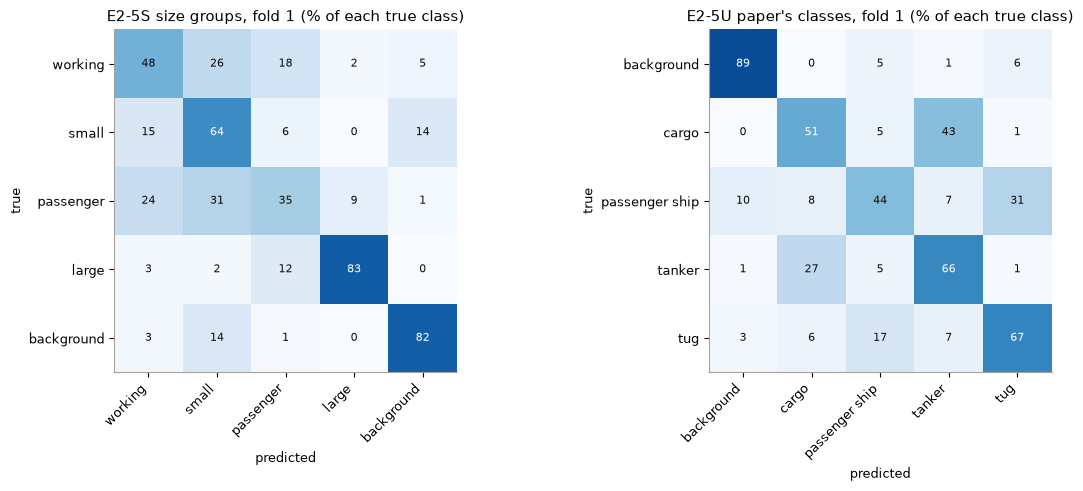

,working,small,passenger,large,background
E2-5S,0.48,0.64,0.35,0.83,0.82


,background,cargo,passenger ship,tanker,tug
E2-5U,0.89,0.51,0.44,0.66,0.67


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (run, title) in zip(axes, ((E2_5S, "E2-5S size groups, fold 1"), (E2_5U, "E2-5U paper's classes, fold 1"))):
    cm, known = confusion(run)
    plot_confusion(ax, cm, known, f"{title} (% of each true class)")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"E2-5S": {nice(c): r for c, r in S[E2_5S]["recall"].items()}}).T.round(2))
display(pd.DataFrame({"E2-5U": {nice(c): r for c, r in S[E2_5U]["recall"].items()}}).T.round(2))

- **E2-5S:** passenger ships are taken for small craft (31 %) or working vessels (24 %); small craft and background
  are confused both ways (a quiet small boat sounds like no ship).
- **E2-5U:** cargo is taken for tanker 43 % of the time and tanker for cargo 27 %, the same main confusion as in the
  dataset's paper; passenger ships are taken for tugs 31 %.
- **Passenger ships are the weakest class in both:** 13 test ships in fold 1, 110 in the whole dataset.

### 9.4 How the 5-class models trained

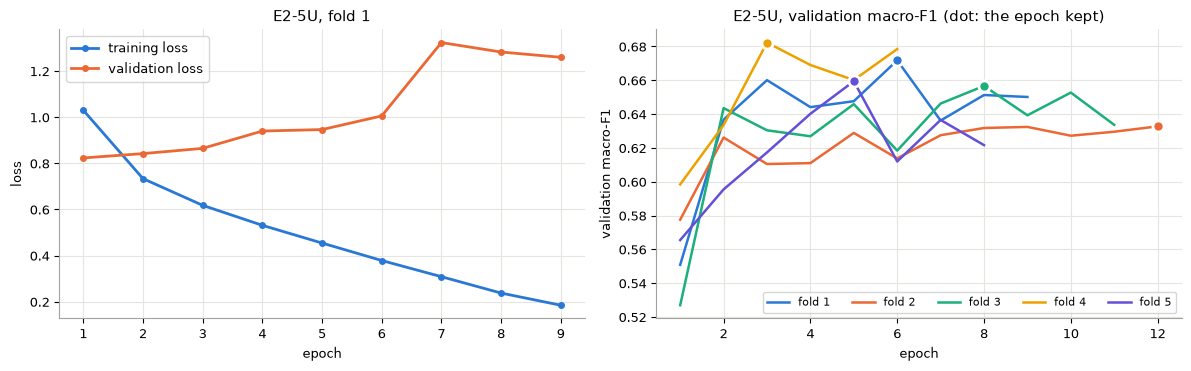

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
lg = log(E2_5U)
axes[0].plot(lg.epoch, lg.train_loss, color=BLUE, lw=2, marker="o", ms=4, label="training loss")
axes[0].plot(lg.epoch, lg.val_loss, color=ORANGE, lw=2, marker="o", ms=4, label="validation loss")
axes[0].set_title("E2-5U, fold 1"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
for k, run in enumerate(FOLDS_5U, 1):
    lg = log(run)
    best = lg.val_metric.idxmax()
    axes[1].plot(lg.epoch, lg.val_metric, lw=1.8, color=[BLUE, ORANGE, AQUA, "#eda100", "#6250d6"][k - 1], label=f"fold {k}")
    axes[1].plot(lg.epoch[best], lg.val_metric[best], "o", ms=8, color=[BLUE, ORANGE, AQUA, "#eda100", "#6250d6"][k - 1],
                 markeredgecolor="white", markeredgewidth=2)
axes[1].set_title("E2-5U, validation macro-F1 (dot: the epoch kept)"); axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation macro-F1"); axes[1].legend(ncol=5, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

Validation loss is lowest in the first epoch and then rises while training loss keeps falling, and validation
macro-F1 peaks within a few epochs: memorising starts early here too. Fold 2 was still improving when it reached the 12-epoch limit of `fast.yaml`.

### 9.5 All 5 folds of the paper's task

One fold can be lucky or unlucky (section 5), so E2-5U was trained and tested on all 5 folds, as in the paper.
`±` is the standard deviation over the folds.

In [24]:
rows = {}
for k, run in enumerate(FOLDS_5U, 1):
    s = S[run]
    rows[f"fold {k}"] = {"test clips": f"{s['test clips']:,}", "background share": pct(s["background share"]),
                         "accuracy": pct(s["accuracy"]), "balanced accuracy": pct(s["balanced accuracy"]),
                         "macro-F1": f"{s['macro-F1']:.3f}", "per ship": f"{pct(s['per ship'])} ({s['ships (>= 3 clips)']})",
                         "ECE after": f"{s['ECE after']:.3f}", "epochs (best)": f"{s['epochs']} ({s['best epoch']})"}
rows["mean ± std"] = {"accuracy": pm([S[r]["accuracy"] for r in FOLDS_5U]),
                      "balanced accuracy": pm([S[r]["balanced accuracy"] for r in FOLDS_5U]),
                      "macro-F1": pm([S[r]["macro-F1"] for r in FOLDS_5U], percent=False),
                      "per ship": pm([S[r]["per ship"] for r in FOLDS_5U])}
display(pd.DataFrame(rows).T.fillna(""))

fold_recall = pd.DataFrame({f"fold {k}": S[run]["recall"] for k, run in enumerate(FOLDS_5U, 1)}).T
fold_recall.loc["mean"] = fold_recall.mean()
display(fold_recall.rename(columns=nice).round(2))

,test clips,background share,accuracy,balanced accuracy,macro-F1,per ship,ECE after,epochs (best)
fold 1,"2,250",16.1 %,62.8 %,63.5 %,0.632,77.9 % (86),0.026,9 (6)
fold 2,953,38.8 %,73.1 %,67.8 %,0.660,74.1 % (27),0.050,12 (12)
fold 3,"1,661",21.9 %,67.2 %,66.4 %,0.653,75.9 % (58),0.038,11 (8)
fold 4,"1,535",23.6 %,68.3 %,67.1 %,0.663,63.0 % (54),0.033,6 (3)
fold 5,"1,887",18.9 %,62.4 %,62.7 %,0.615,66.2 % (68),0.071,8 (5)
mean ± std,,,66.8 ± 4.4 %,65.5 ± 2.3 %,0.644 ± 0.020,71.4 ± 6.5 %,,


,background,cargo,passenger ship,tanker,tug
fold 1,0.89,0.51,0.44,0.66,0.67
fold 2,0.94,0.73,0.41,0.47,0.83
fold 3,0.93,0.66,0.34,0.60,0.79
fold 4,0.97,0.75,0.58,0.39,0.66
fold 5,0.87,0.67,0.40,0.42,0.77
mean,0.92,0.66,0.44,0.51,0.75


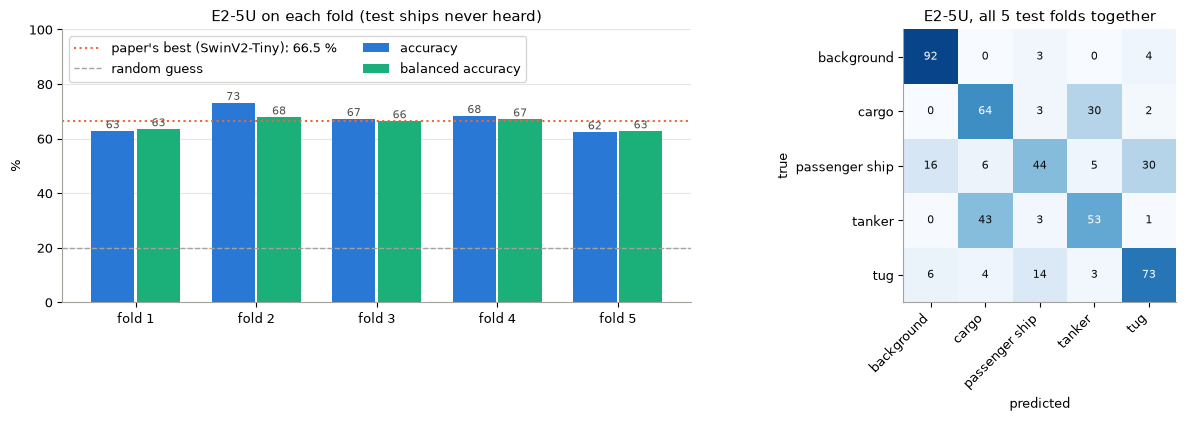

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(5)
acc = [100 * S[r]["accuracy"] for r in FOLDS_5U]
bal = [100 * S[r]["balanced accuracy"] for r in FOLDS_5U]
axes[0].bar(x - 0.19, acc, width=0.36, color=BLUE, label="accuracy")
axes[0].bar(x + 0.19, bal, width=0.36, color=AQUA, label="balanced accuracy")
for i in x:
    axes[0].text(i - 0.19, acc[i] + 1, f"{acc[i]:.0f}", ha="center", color=INK, fontsize=8)
    axes[0].text(i + 0.19, bal[i] + 1, f"{bal[i]:.0f}", ha="center", color=INK, fontsize=8)
axes[0].axhline(66.5, ls=":", color=ORANGE, lw=1.5, label="paper's best (SwinV2-Tiny): 66.5 %")
axes[0].axhline(20, ls="--", color=GREY, lw=1, label="random guess")
axes[0].set_xticks(x, [f"fold {k}" for k in range(1, 6)]); axes[0].set_ylim(0, 100); axes[0].grid(axis="x", visible=False)
axes[0].set_ylabel("%"); axes[0].legend(loc="upper left", ncol=2); axes[0].set_title("E2-5U on each fold (test ships never heard)")
cm, known = confusion(FOLDS_5U)
plot_confusion(axes[1], cm, known, "E2-5U, all 5 test folds together")
plt.tight_layout(); plt.show()

- **66.8 ± 4.4 % accuracy, 65.5 ± 2.3 % balanced accuracy, macro-F1 0.644 ± 0.020** over the 5 folds.
- **Balanced accuracy is the fairer number here.** Background, the easiest class, makes up 16-39 % of our test sets,
  which lifts fold 2's accuracy to 73 %. Balanced accuracy counts every class equally, like the paper's test sets,
  which are balanced by duration.
- **Tanker and passenger ship are the weak classes on every fold.** Over all folds, tanker is taken for cargo 43 % of
  the time and passenger ships for tugs 30 %.
- Deciding once per ship (section 6.3) gives 71.4 ± 6.5 %.

### 9.6 Against the dataset's own paper

Hashemi, Stout, Hoogs and Parham, "UniqueShip: Mitigating Data Leakage in Acoustic Ship Classification Benchmark
Datasets", OCEANS 2026 (arXiv 2609.13659), Table III. The paper reports results only for these 5 classes, on its
"5 Class – Balanced" set with **42 h 40 min of audio per class**, 8.5 times our 5 hours. Its numbers are typed in
below; ours are computed.

,audio per class,accuracy,F1
Paper: MobileNetV3-Small (CNN),42.7 h,61.7 ± 1.2 %,0.607 ± 0.018
Paper: ViT-B/16 (transformer),42.7 h,65.0 ± 2.7 %,0.640 ± 0.035
Paper: SwinV2-Tiny (transformer),42.7 h,66.5 ± 1.2 %,0.656 ± 0.017
"Ours: E2-5U, EfficientNet-B0 (CNN), fold 1",5 h,62.8 %,0.632
"Ours: E2-5U, mean of 5 folds",5 h,66.8 ± 4.4 % (balanced 65.5 ± 2.3 %),0.644 ± 0.020


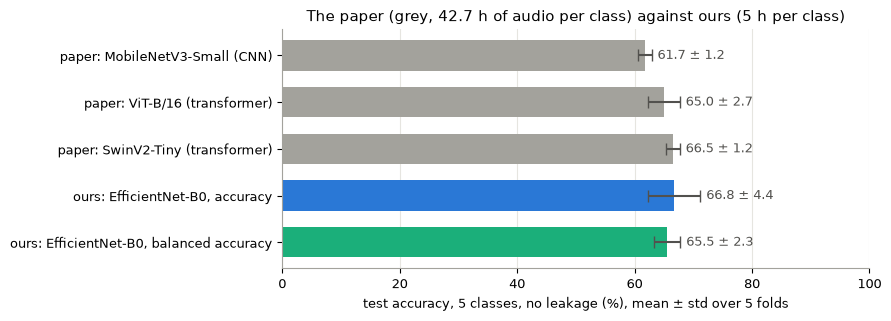

,fair split,leaky split
"Paper: SwinV2-Tiny, 5 classes",66.5 %,82.6 %
"Ours: E2 → E5, 12 classes",32.4 %,85.8 %


In [26]:
paper = {  # Table III, "No Leakage", Mel spectrograms: accuracy and F1, mean ± std over its 5 folds
    "Paper: MobileNetV3-Small (CNN)": (0.617, 0.012, 0.607, 0.018),
    "Paper: ViT-B/16 (transformer)": (0.650, 0.027, 0.640, 0.035),
    "Paper: SwinV2-Tiny (transformer)": (0.665, 0.012, 0.656, 0.017)}
acc5 = np.array([S[r]["accuracy"] for r in FOLDS_5U])
bal5 = np.array([S[r]["balanced accuracy"] for r in FOLDS_5U])
f15 = np.array([S[r]["macro-F1"] for r in FOLDS_5U])
versus = {name: {"audio per class": "42.7 h", "accuracy": f"{100 * a:.1f} ± {100 * sa:.1f} %", "F1": f"{f:.3f} ± {sf:.3f}"}
          for name, (a, sa, f, sf) in paper.items()}
versus["Ours: E2-5U, EfficientNet-B0 (CNN), fold 1"] = {"audio per class": "5 h", "accuracy": pct(S[E2_5U]["accuracy"]),
                                                       "F1": f"{S[E2_5U]['macro-F1']:.3f}"}
versus["Ours: E2-5U, mean of 5 folds"] = {"audio per class": "5 h",
                                          "accuracy": f"{pm(acc5)} (balanced {pm(bal5)})", "F1": pm(f15, percent=False)}
display(pd.DataFrame(versus).T)

bars = [(name.replace("Paper: ", "paper: "), a, sa, GREY) for name, (a, sa, _, _) in paper.items()]
bars += [("ours: EfficientNet-B0, accuracy", acc5.mean(), acc5.std(ddof=1), BLUE),
         ("ours: EfficientNet-B0, balanced accuracy", bal5.mean(), bal5.std(ddof=1), AQUA)]
fig, ax = plt.subplots(figsize=(9, 3.3))
for i, (name, a, sa, colour) in enumerate(bars):
    ax.barh(i, 100 * a, xerr=100 * sa, color=colour, height=0.65, capsize=4, ecolor=INK)
    ax.text(100 * (a + sa) + 1, i, f"{100 * a:.1f} ± {100 * sa:.1f}", va="center", color=INK)
ax.set_yticks(range(len(bars)), [b[0] for b in bars]); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("test accuracy, 5 classes, no leakage (%), mean ± std over 5 folds")
ax.set_title("The paper (grey, 42.7 h of audio per class) against ours (5 h per class)")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"fair split": {"Paper: SwinV2-Tiny, 5 classes": "66.5 %", "Ours: E2 → E5, 12 classes": pct(S[E2]["accuracy"])},
                      "leaky split": {"Paper: SwinV2-Tiny, 5 classes": "82.6 %", "Ours: E2 → E5, 12 classes": pct(S[E5]["accuracy"])}}))

- **Our CNN is level with the paper's two transformers and above its MobileNet**, with 8.5 times less audio per
  class. Within the spreads, the differences are small.
- **The test ships are not the same:** the paper's folds come from its larger 5-class set, ours from the 12-class
  subset keeping only these 5 classes. Our smaller test sets give a larger spread (± 4.4 against ± 1.2).
- **Possible reasons, not tested:** our spectrogram keeps more low-frequency detail (32 kHz audio, a 4,096-sample
  window, 128 mel bands from 10 Hz, against 20 kHz audio, a 1,024-sample window and resized images);
  EfficientNet-B0 is a larger CNN than MobileNetV3-Small; our learning rate is much higher (3e-4 against 1e-6).
- **More hours of the same ships would help little.** In the paper's tests, doubling the audio of the same ships adds
  0.8-1.3 points; doubling the number of different ships adds 2.4-2.6. Their 65 GB / 1.4 TB releases contain the
  same ships as ours, only longer, so about +2.5 to +4 points: not worth the download on this laptop.
- **The same findings as ours:** leakage inflates accuracy (table above), the models key on the individual ship,
  and cargo against tanker is the main confusion.

## 10. What it all means

1. **On ships it has never heard, the 12-class CNN reaches 32 %** (9 classes: 37 %), no better than gradient-boosted
   trees on simple sound statistics. With the test ships heard in training (leaky split) the same model reaches
   86 %. The difference shows the model learns **individual ships, not ship types**: several classes have too few
   different ships to learn a general sound from.
2. **With 5 broader classes the same CNN reaches 63-67 %**, above the 60 % aimed for: 66.8 ± 4.4 % over 5 folds on
   the dataset paper's own task (balanced accuracy 65.5 ± 2.3 %), level with the paper's best model, which had 8.5
   times more audio per class.
3. **Confidence can be made trustworthy on average** with temperature scaling (ECE 0.33 → 0.09 for 12 classes,
   0.18 → 0.03 for 5), and answering only the most confident clips raises accuracy a lot (5 classes: about 90 % on
   the most confident 20 %). Deciding once per ship helps too.
4. **What does not work yet:** unknown ship types are not detected (AUROC about 0.5), added noise makes the model
   *more* confident, a different hydrophone costs about 7 points, and accuracy falls with distance.
5. **Distance and speed** are estimated better than guessing, but no better by the CNN than by the baseline.

## 11. Limitations and next steps

- **One random seed, and 5 folds only for E2-5U** (and the classical baseline). Differences of a few points between
  fold-1 results are within noise.
- **Few ships in some classes**: pilot vessel 2, dredger 6, rescue 23; they dominate some folds' test sets.
- **The size groups (E2-5S) were chosen after estimates on the same test set**, so E2-5S is slightly optimistic.
- Two hydrophones at one place, one ship at a time, ships up to about 2 km away.

Next, in order of expected gain: decide per ship passage rather than per clip; answer only when confident (threshold
chosen on validation); augmentation that changes ship identity but keeps the class (mixing ships of the same class,
pitch shifts, recorded background noise); sampling balanced by ship; gentler fine-tuning and a transformer backbone
as in the paper. Which 5-class grouping to use is to agree with the professor.

## 12. Reproduce

Each run is one command (README section 4); a CNN run takes 15-90 minutes on the laptop.
```
python src/baseline_classical.py --fold 1                                      # E1 (--fold 2..5; --features rich)
python src/train.py --task class                                               # E2
python src/evaluate.py runs/class_f1_efficientnet_b0_vessel --mc 20 --noise 20 10 0     # E2 scores, E8
python src/train.py --task class --split-mode leaky                            # E5
python src/train.py --task class --hydrophone-shift                            # E7
python src/train.py --task class --holdout A --config configs/fast.yaml        # E3 (also B, C)
python src/train.py --task distance --init-from runs/class_f1_efficientnet_b0_vessel/best.pt --config configs/fast.yaml   # E9
python src/train.py --task speed --init-from runs/class_f1_efficientnet_b0_vessel/best.pt --config configs/fast.yaml      # E10
python src/train.py --task class --merge-into-other pilotvessel dredger rescue --config configs/fast.yaml                 # E2-9
python src/train.py --task class --grouping shipsear5 --config configs/fast.yaml                                         # E2-5S
python src/train.py --task class --grouping uniqueship5 --config configs/fast.yaml --fold 1                              # E2-5U (folds 1-5)
python src/evaluate.py runs/<run name>                                         # after every training run
```
Then run this notebook again: every table and figure above is recomputed from the new files.